# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers


# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

### Q1. What is CLIP?

**Answer:**

Contrastive Language–Image Pre-training is a vision-language model that learns a *shared embedding space* in which an image and a sentence describing the same thing are close (high cosine similarity) and unrelated pairs are far apart. This enables zero-shot classification, retrieval, and prompt-based use without task-specific training.

### Q2. What are its two main components?

**Answer:**

1. *Image encoder*: Vision Transformer, ViT-B/32 (the image is cut into 32×32-pixel patches, 12 Transformer layers, width 768), followed by a linear projection to 512-d.
2. *Text encoder*: a 12-layer Transformer (width 512, causal attention, max 77 tokens) whose end-of-text token is projected to the same 512-d space.

The image encoder and text encoder are trained jointly with a symmetric contrastive (InfoNCE) loss over a batch of image–text pairs, with a learned temperature (`logit_scale`, here 100).

### Q3. What is the role of `CLIPProcessor`?

**Answer:**

It is the *pre-processing* wrapper that turns raw inputs into tensors the model accepts. It bundles:

- A `CLIPImageProcessor`: resizes the shorter side to 224 pixels using bicubic interpolation, centre-crops to 224×224, rescales to [0,1], and normalises with CLIP's mean/std → `pixel_values` of shape `(N, 3, 224, 224)`.
- A `CLIPTokenizer`: uses byte-pair encoding of the text (49 408-token vocabulary), adds start/end tokens, and pads or truncates to ≤ 77 tokens → `input_ids`, `attention_mask`.

### Q4. What is the role of `CLIPModel`?

**Answer:**

It holds the **trained network**: the vision tower, the text tower, the two projection layers and `logit_scale`. Its forward pass returns `logits_per_image` / `logits_per_text` (scaled cosine similarities) and the embeddings. `get_image_features` / `get_text_features` (or `vision_model` / `text_model` + projections, as in my helpers) give embeddings directly for retrieval.


In [1]:
!pip install -q transformers torch torchvision pillow matplotlib pandas

In [2]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cpu


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

### Q5. What is the size of the image? 
**Answer:**
image.size = (2989, 4000)` → **2989 px wide × 4000 px high**
 

Image size: (2989, 4000)
Image mode: RGB


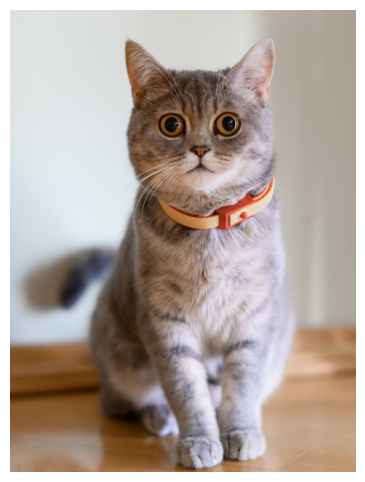

In [3]:
IMAGE_PATH = "images/cat5.jpg"

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

### Q6. What type of data is stored in the PIL image object?
**Answer:**
A 2-D grid of **pixels**. In mode `RGB` every pixel is a triplet of three 8-bit unsigned integers (red, green, blue, each 0–255), so the image is equivalent to an array of shape `(height, width, 3)` and dtype `uint8` (see the NumPy cell below). It is raw intensity data — no semantics; the models must learn semantics from it. Before being fed to a network it is converted to a float tensor `(3, H, W)` and normalised.

In [4]:
import numpy as np
from IPython.display import display
arr = np.array(image)
print("PIL .size  (width, height):", image.size)
print("PIL .mode                 :", image.mode, "-> channels:", image.getbands())
print("As NumPy array (H, W, C)  :", arr.shape, "| dtype:", arr.dtype, "| min/max:", arr.min(), arr.max())
print("Pixel (0, 0) as (R, G, B) :", image.getpixel((0, 0)))
print("Number of pixels          :", image.size[0] * image.size[1], f"(~{image.size[0]*image.size[1]/1e6:.1f} megapixels)")
px = processor(images=image, return_tensors="pt")["pixel_values"]
print("What CLIP actually sees   :", tuple(px.shape), "(resized + centre-cropped to 224x224, normalised)")

PIL .size  (width, height): (2989, 4000)
PIL .mode                 : RGB -> channels: ('R', 'G', 'B')
As NumPy array (H, W, C)  : (4000, 2989, 3) | dtype: uint8 | min/max: 0 255
Pixel (0, 0) as (R, G, B) : (218, 222, 221)
Number of pixels          : 11956000 (~12.0 megapixels)
What CLIP actually sees   : (1, 3, 224, 224) (resized + centre-cropped to 224x224, normalised)


## Exercise 3 — Image/Text similarity


### Questions

### Q7. Which description has the highest probability?

**Answer:**

**"a photo of a cat" — 0.9879**, far ahead of "a photo of a dog" (0.0071), "a photo of a person" (0.0045), "a photo of a horse" (0.0004) and "a photo of a car" (0.0001).


### Q8. Is it compatible with the actual image?

**Answer:**

Yes. The image shows a cat


### Q9.Why can CLIP compare an image with a sentence?  

**Answer:**

Because both are mapped into **the same 512-dimensional vector space** by two encoders that were trained *together* with a contrastive objective: for each real (image, caption) pair the similarity is pushed up, for the other N−1 captions in the batch it is pushed down. After training, "meaning" is encoded geometrically, so an image vector and a sentence vector can be compared directly with a cosine similarity (a dot product of L2-normalised vectors). The score shown by the model is `100 × cosine`.


### Q10. What does `softmax()` do?
**Answer:**
It converts a vector of raw scores (logits) $z_i$ into a probability distribution


In [5]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.9879
a photo of a dog                   : 0.0071
a photo of a car                   : 0.0001
a photo of a horse                 : 0.0004
a photo of a person                : 0.0045


***helper functions used by the rest of the lab (robust across `transformers` versions)***


In [6]:
import numpy as np
from IPython.display import display

@torch.no_grad()
def clip_image_features(images):
    """L2-normalised CLIP image embeddings, shape (N, 512)."""
    if not isinstance(images, (list, tuple)):
        images = [images]
    inputs = processor(images=list(images), return_tensors="pt").to(device)
    pooled = model.vision_model(pixel_values=inputs["pixel_values"]).pooler_output   # (N, 768)
    feats = model.visual_projection(pooled)                                          # (N, 512)
    return feats / feats.norm(dim=-1, keepdim=True)

@torch.no_grad()
def clip_text_features(texts):
    """L2-normalised CLIP text embeddings, shape (N, 512)."""
    inputs = processor(text=list(texts), return_tensors="pt", padding=True, truncation=True).to(device)
    pooled = model.text_model(input_ids=inputs["input_ids"],
                              attention_mask=inputs["attention_mask"]).pooler_output  # (N, 512)
    feats = model.text_projection(pooled)                                             # (N, 512)
    return feats / feats.norm(dim=-1, keepdim=True)

CLIP_SCALE = model.logit_scale.exp().item()      # = 1 / temperature
print(f"logit_scale = {CLIP_SCALE:.1f}  ->  score = {CLIP_SCALE:.0f} x cosine similarity")
print("Embedding dim:", model.config.projection_dim)
print("Image encoder:", model.config.vision_config.num_hidden_layers, "layers, width",
      model.config.vision_config.hidden_size, ", patch size", model.config.vision_config.patch_size)
print("Text encoder :", model.config.text_config.num_hidden_layers, "layers, width",
      model.config.text_config.hidden_size, ", max length", model.config.text_config.max_position_embeddings)

logit_scale = 100.0  ->  score = 100 x cosine similarity
Embedding dim: 512
Image encoder: 12 layers, width 768 , patch size 32
Text encoder : 12 layers, width 512 , max length 77


## Exercise 4 — Zero-shot classification


### Questions

### Q11. What is zero-shot classification?

**Answer:**

Classifying images into categories **the model was never explicitly trained to recognise as labels**, using only a textual description of each category. With CLIP: write one prompt per class ("a photo of a *cat*"), embed the prompts, embed the image, and predict the class whose text embedding is most similar. The set of classes is chosen at inference time and can be changed freely.

### Q12. Why is it not necessary to train a new classifier?

**Answer:**

Because the "classifier weights" are produced by the **text encoder**: the embedding of the class prompt plays the role of the weight vector of a linear classifier, and the image embedding is the feature. CLIP's pre-training on 400M captions already taught the encoders a broad visual vocabulary aligned with language, so no labelled dataset, no gradient step and no new output layer are needed — only a list of class names.

In [7]:
# STUDENT TASK
def classify_image(image, classes):
    # Convert class names into text prompts
    texts = [f"a photo of a {cls}" for cls in classes]

    # Preprocess image and text
    inputs = processor(
        text=texts,
        images=image,
        return_tensors="pt",
        padding=True
    ).to(device) 

    # Compute CLIP scores
    with torch.no_grad():
        outputs = model(**inputs)

    # Get image-text scores
    scores = outputs.logits_per_image[0]

    # Convert scores to probabilities
    probabilities = scores.softmax(dim=0)

    # Get the class with the highest probability
    best_idx = probabilities.argmax().item()

    return classes[best_idx], probabilities[best_idx].item()

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

prediction, probability = classify_image(image, classes)
print("Prediction:", prediction)
print("Probability:", probability)

Prediction: cat
Probability: 0.9919579029083252


### Q13. What happens if the correct class is not included in the candidate classes?

**Answer:**

The softmax forces the probabilities to sum to 1 over the candidate list, so CLIP **still returns a winner** — the "least wrong" class — and often with a deceptively high CLIP still chooses the closest class from the available candidates, even if none is correct. Softmax assigns probabilities that sum to 1, which can make the prediction look more confident than it really is.

In [8]:
cat_image = Image.open("images/cat1.jpg").convert("RGB")
all_classes = ["cat", "dog", "car", "airplane", "horse", "bird"]
no_cat = [c for c in all_classes if c != "cat"]

img_f = clip_image_features(cat_image)
for name, cl in [("'cat' IS a candidate", all_classes), ("'cat' is NOT a candidate", no_cat)]:
    pred, p = classify_image(cat_image, cl)
    cos = (img_f @ clip_text_features([f"a photo of a {c}" for c in cl]).T)[0]
    print(f"{name:26s} -> predicted '{pred}' with p = {p:.2%} | best raw cosine = {cos.max().item():.3f}")

'cat' IS a candidate       -> predicted 'cat' with p = 99.43% | best raw cosine = 0.284
'cat' is NOT a candidate   -> predicted 'dog' with p = 70.25% | best raw cosine = 0.229


## Exercise 5 — Evaluate CLIP

### Questions

### Q14. What is the obtained accuracy?  
**Answer:**
**10 / 10 correct → Accuracy = 10/10 = 100 %**, with confidences between 99.28 % and 99.91 %. 


### Q15. Which images are incorrectly classified?  
**Answer:**
**None** — every one of `cat1…cat5` and `dog1…dog5` is correctly classified (see the table).


### Q16. Give at least two possible reasons for the errors.
**Answer:**
**No errors occurred in this exercise**, but possible reasons for misclassification on more difficult images include:

1. Ambiguous images: The animal may be partially hidden, very small, in an unusual pose, or appear with another animal.

2. Image preprocessing: CLIPProcessor resizes and centre-crops images to 224 × 224 pixels. This may cut out an animal near the edge of the image and remove important details.


In [9]:
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ("cat3.jpg", "cat"),
    ("cat4.jpg", "cat"),
    ("cat5.jpg", "cat"),
    ("dog1.jpg", "dog"),
    ("dog2.jpg", "dog"),
    ("dog3.jpg", "dog"),
    ("dog4.jpg", "dog"),
    ("dog5.jpg", "dog"),
]

classes = ["cat", "dog"]

correct = 0
records = []   
total = len(dataset)
folder='images/'
for image_path, true_label in dataset:
    # Load image
    image = Image.open(folder+image_path).convert("RGB")

    # Predict class
    predicted_class, probability = classify_image(image, classes)

    # Evaluate prediction
    is_correct = predicted_class == true_label
    correct += int(is_correct)
    records.append({"Image": image_path, "Actual": true_label, "Predicted": predicted_class,
                    "Probability": probability, "Correct": is_correct})

    print(
        f"Image: {image_path} | "
        f"True: {true_label} | "
        f"Predicted: {predicted_class} | "
        f"Probability: {probability:.2%} | "
        f"Correct: {is_correct}"
    )

# Calculate accuracy
accuracy = correct / total

print(f"\nCorrect predictions: {correct}/{total}")
print(f"Accuracy: {accuracy:.2%}")

Image: cat1.jpg | True: cat | Predicted: cat | Probability: 99.60% | Correct: True
Image: cat2.jpg | True: cat | Predicted: cat | Probability: 99.46% | Correct: True
Image: cat3.jpg | True: cat | Predicted: cat | Probability: 99.71% | Correct: True
Image: cat4.jpg | True: cat | Predicted: cat | Probability: 99.30% | Correct: True
Image: cat5.jpg | True: cat | Predicted: cat | Probability: 99.28% | Correct: True
Image: dog1.jpg | True: dog | Predicted: dog | Probability: 99.90% | Correct: True
Image: dog2.jpg | True: dog | Predicted: dog | Probability: 99.57% | Correct: True
Image: dog3.jpg | True: dog | Predicted: dog | Probability: 99.85% | Correct: True
Image: dog4.jpg | True: dog | Predicted: dog | Probability: 99.91% | Correct: True
Image: dog5.jpg | True: dog | Predicted: dog | Probability: 99.75% | Correct: True

Correct predictions: 10/10
Accuracy: 100.00%


**Results table, accuracy, errors (Q14, Q15)**

In [10]:
df_eval = pd.DataFrame(records)
display(df_eval.assign(Probability=df_eval["Probability"].map("{:.2%}".format)))

n_correct, n_total = int(df_eval["Correct"].sum()), len(df_eval)
acc = n_correct / n_total
print(f"Q14 -> Accuracy = N_correct / N_total = {n_correct}/{n_total} = {acc:.2%}")

z = 1.96
centre = (acc + z**2 / (2 * n_total)) / (1 + z**2 / n_total)
half = z * np.sqrt(acc * (1 - acc) / n_total + z**2 / (4 * n_total**2)) / (1 + z**2 / n_total)
print(f"      95% Wilson interval: [{max(0, centre-half):.1%}, {min(1, centre+half):.1%}]")

wrong = df_eval[~df_eval["Correct"]]
if wrong.empty:
    print("Q15 -> no image is misclassified.")
else:
    print("Q15 -> misclassified images:", list(wrong["Image"]))
    fig, axes = plt.subplots(1, len(wrong), figsize=(4 * len(wrong), 4), squeeze=False)
    for ax, (_, r) in zip(axes[0], wrong.iterrows()):
        ax.imshow(Image.open(folder + r["Image"]).convert("RGB")); ax.axis("off")
        ax.set_title(f"{r['Image']}\ntrue={r['Actual']} / pred={r['Predicted']} ({r['Probability']:.0%})")
    plt.show()

print(f"Mean confidence: correct = {df_eval[df_eval.Correct].Probability.mean():.2%}",
      f"| wrong = {wrong.Probability.mean():.2%}" if not wrong.empty else "")

,Image,Actual,Predicted,Probability,Correct
0,cat1.jpg,cat,cat,99.60%,True
1,cat2.jpg,cat,cat,99.46%,True
2,cat3.jpg,cat,cat,99.71%,True
3,cat4.jpg,cat,cat,99.30%,True
4,cat5.jpg,cat,cat,99.28%,True
5,dog1.jpg,dog,dog,99.90%,True
6,dog2.jpg,dog,dog,99.57%,True
7,dog3.jpg,dog,dog,99.85%,True
8,dog4.jpg,dog,dog,99.91%,True
9,dog5.jpg,dog,dog,99.75%,True


Q14 -> Accuracy = N_correct / N_total = 10/10 = 100.00%
      95% Wilson interval: [72.2%, 100.0%]
Q15 -> no image is misclassified.
Mean confidence: correct = 99.63% 


## Exercise 6 — Prompt engineering with CLIP

### Questions

### Q17. Are the scores identical?  
**Answer:**
No. From the CLIP scores (100 × cosine) are 26.30, **28.42**, 27.22, 27.08 and 26.76: five different sentences give five different text embeddings, hence five different similarities with the *same* image — even though a human reads all five as "a cat".


### Q18. Which prompt gives the highest score?  
**Answer:**
**"a photo of a cat"** gives the highest score: 28.42, compared with 26.30 for "a cat".

The more descriptive prompt matches the image better.

### Q19. What does this demonstrate about prompt formulation?
**Answer:**
CLIP is **sensitive to the exact wording** — it is a text encoder trained on web *captions*, so prompts that look like a typical caption ("a photo of a …") sit closer to the training distribution than a bare noun or a dictionary-style definition. Prompt design ("prompt engineering") and 


In [11]:
from PIL import Image
import torch

prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

# Load the same cat image for all prompts
image = Image.open(
    "images/cat1.jpg"
).convert("RGB")

# Preprocess image and prompts
inputs = processor(
    text=prompts,
    images=image,
    return_tensors="pt",
    padding=True
).to(device)  

# Calculate CLIP scores
with torch.no_grad():
    outputs = model(**inputs)

scores = outputs.logits_per_image[0]
probabilities = scores.softmax(dim=0)

# Display and compare results
for prompt, score, probability in zip(
    prompts, scores.tolist(), probabilities.tolist()
):
    print(
        f"Prompt: {prompt}\n"
        f"Score: {score:.4f} | Probability: {probability:.2%}\n"
    )

best_idx = probabilities.argmax().item()

print("Best prompt:", prompts[best_idx])
print(f"Highest probability: {probabilities[best_idx].item():.2%}")

Prompt: a cat
Score: 26.2956 | Probability: 6.37%

Prompt: a photo of a cat
Score: 28.4221 | Probability: 53.41%

Prompt: a photograph showing a cat
Score: 27.2243 | Probability: 16.12%

Prompt: an image containing a cat
Score: 27.0791 | Probability: 13.94%

Prompt: a domestic animal called a cat
Score: 26.7621 | Probability: 10.16%

Best prompt: a photo of a cat
Highest probability: 53.41%


# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

### Q20. Which image is the most similar?

**Answer:** `img6.jpg` is the most similar image according to the cosine similarity ranking.

### Q21. Is it semantically relevant?

**Answer:** Yes, if `img6.jpg` shows people playing football or a football scene. CLIP understands the general meaning of the text and image, but it may also retrieve images of other sports or people with a ball.

### Q22. Why does this method not require image labels?

**Answer:** CLIP converts images and text into vectors in a shared embedding space. It compares them using cosine similarity to find the most similar images. Therefore, images do not need labels because users can search with a text description.

### Q23. Give one real-world application of semantic image retrieval.

**Answer:** E-commerce visual search. For example, a user can search for "a red dress with floral print" to find similar products without manually labeling every image.

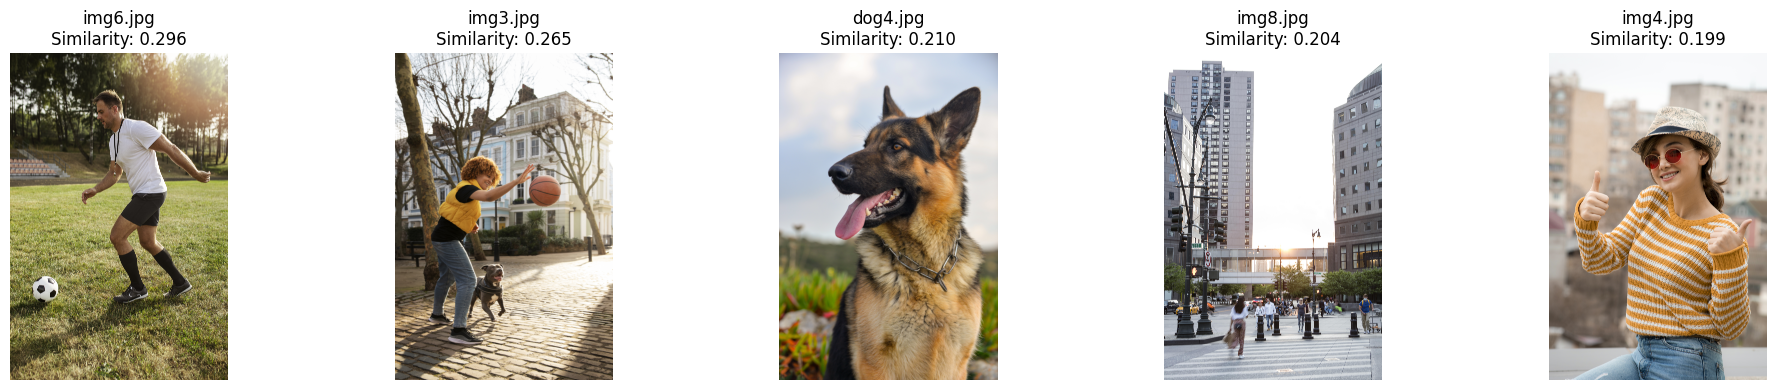

Most similar image: img6.jpg


In [12]:
from pathlib import Path
from PIL import Image
import torch
import matplotlib.pyplot as plt

IMAGE_DIR = "images"
QUERY = "a person playing football"

# Find both JPG and PNG images
image_paths = sorted(
    list(Path(IMAGE_DIR).glob("*.jpg")) +
    list(Path(IMAGE_DIR).glob("*.png"))
)

if not image_paths:
    raise ValueError(
        f"No JPG or PNG images found in {Path(IMAGE_DIR).resolve()}"
    )

image_embeddings = []

# Encode images
for path in image_paths:
    image = Image.open(path).convert("RGB")
    inputs = processor(images=image, return_tensors="pt").to(device)  

    with torch.no_grad():
        outputs = model.get_image_features(**inputs)

    # Newer Transformers versions may return a ModelOutput
    if hasattr(outputs, "pooler_output"):
        embeddings = outputs.pooler_output
    else:
        embeddings = outputs

    # If this is the vision encoder output, project it into CLIP space
    if embeddings.shape[-1] != model.config.projection_dim:
        embeddings = model.visual_projection(embeddings)

    embeddings = embeddings / embeddings.norm(dim=-1, keepdim=True)
    image_embeddings.append(embeddings)

image_embeddings = torch.cat(image_embeddings, dim=0)

# Encode the text query
text_inputs = processor(
    text=[QUERY],
    return_tensors="pt",
    padding=True
).to(device)   

with torch.no_grad():
    outputs = model.get_text_features(**text_inputs)

if hasattr(outputs, "pooler_output"):
    text_features = outputs.pooler_output
else:
    text_features = outputs

if text_features.shape[-1] != model.config.projection_dim:
    text_features = model.text_projection(text_features)

text_features = text_features / text_features.norm(
    dim=-1, keepdim=True
)

# Compare text and image embeddings
similarities = (text_features @ image_embeddings.T).squeeze(0)

top_k = min(5, len(image_paths))
scores, indices = similarities.topk(top_k)

fig, axes = plt.subplots(1, top_k, figsize=(4 * top_k, 4))
if top_k == 1:
    axes = [axes]

for ax, score, idx in zip(axes, scores, indices):
    i = idx.item()
    ax.imshow(Image.open(image_paths[i]).convert("RGB"))
    ax.set_title(
        f"{image_paths[i].name}\nSimilarity: {score.item():.3f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Most similar image:", image_paths[indices[0].item()].name)

In [13]:
db = {"paths": [str(p) for p in image_paths], "embeddings": image_embeddings.detach().cpu()}
torch.save(db, "clip_image_database.pt")
print("Saved", db["embeddings"].shape, "| norms (should be 1):", db["embeddings"].norm(dim=-1)[:3])
all_scores = similarities.detach().cpu()
df_rank = pd.DataFrame({"Image": [p.name for p in image_paths], "Cosine similarity": all_scores.tolist()})
display(df_rank.sort_values("Cosine similarity", ascending=False).head(5).reset_index(drop=True))

Saved torch.Size([20, 512]) | norms (should be 1): tensor([1.0000, 1.0000, 1.0000])


,Image,Cosine similarity
0,img6.jpg,0.295581
1,img3.jpg,0.265120
2,dog4.jpg,0.210321
3,img8.jpg,0.203540
4,img4.jpg,0.199271


# Part C — LLaVA

### Exercise 9 — LLaVA Architecture

**Completed diagram**

Image → Vision Encoder (SigLIP ViT) → Projection Layer (MLP) → Language Model (Qwen2-0.5B) → Text Response

**Note:** Original LLaVA 1.5 uses a CLIP vision encoder and a Vicuna language model. The OneVision model used in this lab uses SigLIP and Qwen2-0.5B. Both follow the same architecture: vision encoder → projector → language model.

### Q24. What is the role of the vision encoder?

**Answer:** The vision encoder converts an image into a sequence of feature vectors representing visual details, such as objects and their positions. These features are passed to the language model through the projection layer.

### Q25. Why is a projection layer required?

**Answer:** The projection layer maps visual features into the format expected by the language model. In this model, it converts features from 1152 dimensions to 896 dimensions, allowing the language model to process visual information alongside text tokens.

### Q26. What is the role of the language model?

**Answer:** The language model combines visual information with the user's question to generate a text response. It handles language understanding, instruction following, and answer generation. However, it can sometimes produce incorrect information or hallucinations.

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [14]:
import torch
from transformers import AutoProcessor, LlavaOnevisionForConditionalGeneration

MODEL_ID = "llava-hf/llava-onevision-qwen2-0.5b-ov-hf"

processor_llava = AutoProcessor.from_pretrained(MODEL_ID)


import gc
globals().pop("llava", None); gc.collect()
if torch.cuda.is_available():
    llava_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    load_kwargs = {"device_map": "auto"}
else:
    llava_dtype = torch.bfloat16
    load_kwargs = {}

llava = LlavaOnevisionForConditionalGeneration.from_pretrained(
    MODEL_ID, 
    torch_dtype=llava_dtype,
    low_cpu_mem_usage=True,
    **load_kwargs
)

llava.eval()

Loading weights:   0%|          | 0/716 [00:00<?, ?it/s]

LlavaOnevisionForConditionalGeneration(
  (model): LlavaOnevisionModel(
    (vision_tower): SiglipVisionModel(
      (embeddings): SiglipVisionEmbeddings(
        (patch_embedding): Conv2d(3, 1152, kernel_size=(14, 14), stride=(14, 14), padding=valid)
        (position_embedding): Embedding(729, 1152)
      )
      (encoder): SiglipEncoder(
        (layers): ModuleList(
          (0-25): 26 x SiglipEncoderLayer(
            (layer_norm1): LayerNorm((1152,), eps=1e-06, elementwise_affine=True, bias=True)
            (self_attn): SiglipAttention(
              (k_proj): Linear(in_features=1152, out_features=1152, bias=True)
              (v_proj): Linear(in_features=1152, out_features=1152, bias=True)
              (q_proj): Linear(in_features=1152, out_features=1152, bias=True)
              (out_proj): Linear(in_features=1152, out_features=1152, bias=True)
            )
            (layer_norm2): LayerNorm((1152,), eps=1e-06, elementwise_affine=True, bias=True)
            (mlp): Sigli

In [15]:
from PIL import Image

def ask_llava(image, question, max_new_tokens=100, max_side=512):
    
    image = image.copy()
    image.thumbnail((max_side, max_side))

    conversation = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": question}
            ]
        }
    ]

    prompt = processor_llava.apply_chat_template(
        conversation,
        add_generation_prompt=True
    )

    inputs = processor_llava(
        text=prompt,
        images=image,
        return_tensors="pt"
    )

    device_ = llava.device
    dtype_ = llava.dtype
    inputs = {k: v.to(device=device_, dtype=dtype_ if v.is_floating_point() else None) for k, v in inputs.items()}

    with torch.no_grad():
        output = llava.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            use_cache=True
        )

    # Decode only the newly generated answer
    answer_tokens = output[:, inputs["input_ids"].shape[1]:]
    answer = processor_llava.batch_decode(
        answer_tokens,
        skip_special_tokens=True
    )[0]

    return answer.strip()

In [16]:
import time
from IPython.display import display

EX10_IMAGE = "images/img6.jpg"
image = Image.open(EX10_IMAGE).convert("RGB")

questions = [
    "What is happening in this image?",
    "How many people are visible?",
    "What objects can you identify?",
    "Describe the image in detail."
]

rows = []
for question in questions:
    t0 = time.perf_counter()
    answer = ask_llava(image, question)
    rows.append({"Question": question, "LLaVA Answer": answer, "Time (s)": round(time.perf_counter() - t0, 1)})
    print("Question:", question)
    print("Answer:", answer)
    print("-" * 50)

df_ex10 = pd.DataFrame(rows)
display(df_ex10)

Question: What is happening in this image?
Answer: In the image, a man is playing soccer on a grassy field. He is wearing a white t-shirt, black shorts, and black socks. He is in the process of kicking a black and white soccer ball. The background of the image features a grassy field with trees and a few bleachers. The man appears to be focused on the ball, indicating that he is actively engaged in the game.
--------------------------------------------------
Question: How many people are visible?
Answer: There is one person visible in the image.
--------------------------------------------------
Question: What objects can you identify?
Answer: In the image, there is a soccer ball, a man, and a person wearing a white shirt and black shorts. The man is wearing a whistle around his neck and is in the process of kicking the soccer ball. The background features a grassy field with trees and a few bleachers.
--------------------------------------------------
Question: Describe the image in d

,Question,LLaVA Answer,Time (s)
0,What is happening in this image?,"In the image, a man is playing soccer on a gra...",118.0
1,How many people are visible?,There is one person visible in the image.,109.8
2,What objects can you identify?,"In the image, there is a soccer ball, a man, a...",114.8
3,Describe the image in detail.,"In the image, a man is captured in the midst o...",118.5


## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions


### Q27. What is the VQA accuracy?

**Answer:**

Accuracy = Correct answers / Total questions.

There are 25 questions (5 images × 5 questions). The accuracy depends on the human evaluation results. An answer is correct only if it is true for the image and answers the question.

### Q28. Which types of questions are difficult for LLaVA?

**Answer:**

LLaVA may struggle with:

- **Counting:** Counting people or small, overlapping objects.
- **Spatial relations:** Identifying locations and what is behind or beside objects.
- **Reading text:** Reading small text, such as writing on a board.
- **False or ambiguous questions:** Answering questions that assume something is present when it is not.
- **Long answers:** Generating extra or incorrect details.

LLaVA usually performs better on simple questions about clearly visible objects and colours.


In [17]:
from pathlib import Path
from PIL import Image
import torch
import pandas as pd
from IPython.display import display

IMAGE_DIR = Path("images")

image_paths = sorted(
    list(IMAGE_DIR.glob("*.jpg")) +
    list(IMAGE_DIR.glob("*.png")) +
    list(IMAGE_DIR.glob("*.jpeg"))
)[:5]

questions = [
    "How many people are visible?",
    "What objects can you see?",
    "Where are the people?",
    "What are they doing?",
    "What is visible in the background?"
]

VQA_IMAGES = ["img6.jpg", "img9.jpg", "dog1.jpg", "img2.jpg", "img3.jpg"]
if VQA_IMAGES:
    image_paths = [IMAGE_DIR / n for n in VQA_IMAGES]

if len(image_paths) < 5:
    print(f"Warning: only {len(image_paths)} images found.")


results = []

for path in image_paths:
    image = Image.open(path).convert("RGB")

    for question in questions:
        try:
            answer = ask_llava(image, question, max_new_tokens=40)
        except Exception as e:
            answer = f"ERROR: {e}"
            print(path.name, question, e)

        results.append({
            "Image": path.name,
            "Question": question,
            "LLaVA Answer": answer,
            "Human Evaluation": ""
        })

        print(path.name, "|", question, "|", answer)

    image.close()

df_vqa = pd.DataFrame(results)
display(df_vqa)
df_vqa.to_csv("vqa_results.csv", index=False) 

img6.jpg | How many people are visible? | There is one person visible in the image.
img6.jpg | What objects can you see? | In the image, there is a man wearing a white shirt and black shorts, playing soccer. He is kicking a soccer ball on a grassy field. The background features trees and a few bleachers
img6.jpg | Where are the people? | The people are on a soccer field.
img6.jpg | What are they doing? | The man is playing soccer.
img6.jpg | What is visible in the background? | In the background, there are trees and a grassy field, which suggests that the man is playing soccer in a park or a similar outdoor recreational area.
img9.jpg | How many people are visible? | There are two people visible in the image, walking hand in hand in a lush green field.
img9.jpg | What objects can you see? | In the image, there are two people walking hand in hand in a lush green field. The sky is clear with a few scattered clouds, and the sun is shining brightly. The landscape is hilly
img9.jpg | Where 

,Image,Question,LLaVA Answer,Human Evaluation
0,img6.jpg,How many people are visible?,There is one person visible in the image.,
1,img6.jpg,What objects can you see?,"In the image, there is a man wearing a white s...",
2,img6.jpg,Where are the people?,The people are on a soccer field.,
3,img6.jpg,What are they doing?,The man is playing soccer.,
4,img6.jpg,What is visible in the background?,"In the background, there are trees and a grass...",
5,img9.jpg,How many people are visible?,"There are two people visible in the image, wal...",
6,img9.jpg,What objects can you see?,"In the image, there are two people walking han...",
7,img9.jpg,Where are the people?,The people are walking in a field.,
8,img9.jpg,What are they doing?,The couple is walking hand in hand in a field ...,
9,img9.jpg,What is visible in the background?,"In the background, there are rolling hills and...",


## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

### Q29. Does the bicycle actually exist?

**Answer:** No. The image shows a cat on green foliage, not a bicycle.

### Q30. Did LLaVA invent information?

**Answer:** It answers that there is no bicycle, it correctly identifies the false assumption in the question.

### Q31. What is a visual hallucination?

**Answer:** A visual hallucination happens when a model describes something that is not supported by the image, such as a non-existent object, an incorrect colour, or a wrong location.

### Q32. Why can a multimodal model hallucinate?

**Answer:** A multimodal model can hallucinate for several reasons:

- **Language bias:** It generates plausible answers even when visual evidence is missing.
- **Limited visual understanding:** Small models or low-resolution images can make details difficult to recognize.
- **Training data:** The model may learn incorrect or unsupported information.
- **Leading questions:** A question can suggest that an object exists, encouraging the model to invent details.



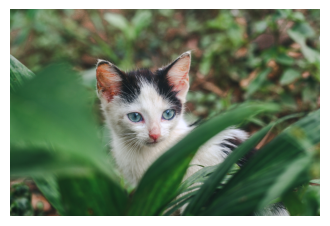

,Question,LLaVA Answer
0,Is there a bicycle in this image?,no
1,What color is the bicycle?,The bicycle is not visible in the image.
2,Where is the bicycle located?,"The bicycle is located in the middle of the image, surrounded by green plants."


PLAYS ALONG (possible hallucination) <- Is there a bicycle in this image?
denies existence       <- What color is the bicycle?
PLAYS ALONG (possible hallucination) <- Where is the bicycle located?

(The heuristic is only a hint: read the answers and decide yourself.)


In [18]:
NO_BICYCLE_IMAGE = "images/cat1.jpg"      
img_nb = Image.open(NO_BICYCLE_IMAGE).convert("RGB")
plt.figure(figsize=(4, 4)); plt.imshow(img_nb); plt.axis("off"); plt.show()

bike_questions = [
    "Is there a bicycle in this image?",
    "What color is the bicycle?",
    "Where is the bicycle located?",
]
rows = []
for q in bike_questions:
    a = ask_llava(img_nb, q, max_new_tokens=60)
    rows.append({"Question": q, "LLaVA Answer": a})
df_halluc = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 200)
display(df_halluc)

# quick heuristic: does the answer deny the (non-existent) bicycle, or play along with the false premise?
deny = ["no bicycle", "not a bicycle", "no bike", "there is no", "there are no", "not visible", "not present",
        "doesn't", "does not", "cannot", "can't", "isn't", "is not", "no, "]
for q, a in zip(bike_questions, df_halluc["LLaVA Answer"]):
    denies = any(d in a.lower() for d in deny)
    print(f"{'denies existence      ' if denies else 'PLAYS ALONG (possible hallucination)'} <- {q}")
print("\n(The heuristic is only a hint: read the answers and decide yourself.)")

# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

### Comparison Table — CLIP vs LLaVA

| Property | CLIP | LLaVA |
|---|---|---|
| Input | An image and candidate texts, encoded separately by two encoders | An image plus a text instruction or question, processed together |
| Main output | Embeddings and similarity scores (probabilities over the given candidates) | Generated natural-language text, token by token |
| Zero-shot classification | **Native:** scores candidate classes in one forward pass, but must choose from the given list (Q13) | Possible through prompting, but answers are free text and must be parsed; slower |
| Image retrieval | **Native and scalable:** embed images once, then search using cosine similarity or an ANN index | Not designed for this; useful for re-ranking or explaining a few candidates |
| Text generation | No — cannot generate sentences | **Yes** — captions, explanations, dialogue |
| VQA | No — can only score pre-written candidate answers | **Yes** — answers questions about images |
| Open-ended response | No — compares a fixed set of provided texts | **Yes** |

### Q33. Which model is better suited to image classification?

**Answer:** **CLIP** is better suited to image classification because it quickly scores a fixed set of candidate labels. Its scores are easy to evaluate and threshold. In my experiment, it correctly classified 10/10 images with at least 99% confidence. LLaVA can also classify images, but it is slower and generates text answers.

### Q34. Which model is better for image description?

**Answer:** **LLaVA** is better because it generates detailed sentences describing objects, colours, positions, and relationships. CLIP can only compare an image with descriptions written in advance.

### Q35. Which model is better for visual question answering?

**Answer:** **LLaVA** is better because it generates answers to questions about objects, colours, locations, counting, and actions. CLIP can only compare the image with pre-written candidate answers. However, LLaVA can hallucinate details that are not present in the image.

### Q36. What is the fundamental difference between CLIP and LLaVA?

**Answer:** CLIP is a **contrastive dual-encoder** that learns to align image and text embeddings and measures their similarity. LLaVA is a **generative multimodal language model** that uses visual features and a text prompt to generate a response.

**In short: CLIP matches; LLaVA talks.** LLaVA also uses a vision encoder, such as SigLIP in the model used in this lab.


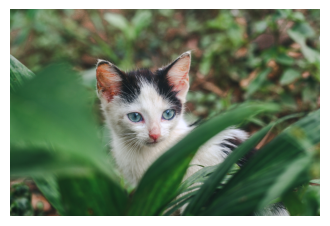

CLIP
  a photo of a cat     score= 28.42  probability=99.55%
  a photo of a dog     score= 22.91  probability=0.40%
  a photo of a horse   score= 20.74  probability=0.05%
  time: 0.17 s | output: 3 numbers, no text

LLaVA
  A kitten is present in the image. It has a white coat with black and orange patches, and striking blue eyes.
  time: 111.2 s | output: free text

LLaVA is about 670x slower than CLIP on this image.


In [19]:
COMPARE_IMAGE = "images/cat1.jpg"
img_cmp = Image.open(COMPARE_IMAGE).convert("RGB")
plt.figure(figsize=(4, 4)); plt.imshow(img_cmp); plt.axis("off"); plt.show()

def sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

# ---- CLIP -------------------------------------------------------------------------------------
cands = ["a photo of a cat", "a photo of a dog", "a photo of a horse"]
sync(); t0 = time.perf_counter()
logits_cmp = CLIP_SCALE * (clip_image_features(img_cmp) @ clip_text_features(cands).T)[0]
probs_cmp = logits_cmp.softmax(dim=0).cpu()
sync(); t_clip = time.perf_counter() - t0
print("CLIP")
for c, l, p in zip(cands, logits_cmp.tolist(), probs_cmp.tolist()):
    print(f"  {c:20s} score={l:6.2f}  probability={p:.2%}")
print(f"  time: {t_clip:.2f} s | output: {len(cands)} numbers, no text")

# ---- LLaVA ------------------------------------------------------------------------------------
t0 = time.perf_counter()
llava_answer = ask_llava(img_cmp, "What animal is present in the image? Describe its appearance.", max_new_tokens=120)
t_llava = time.perf_counter() - t0
print("\nLLaVA")
print(" ", llava_answer)
print(f"  time: {t_llava:.1f} s | output: free text")
print(f"\nLLaVA is about {t_llava / max(t_clip, 1e-6):.0f}x slower than CLIP on this image.")

# Final Mini-Project

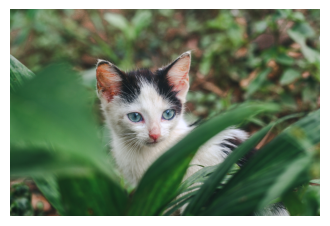

Q: What is happening in this image?
CLIP tags: cat (99%), dog (0%), person (0%)
A: In the image, there is a small kitten with striking blue eyes peeking out from behind some green leaves. The kitten appears to be curious and alert, possibly observing its surroundings or looking for something. The background is blurred, which helps to focus attention on the kitten, making it the central subject of the photograph.


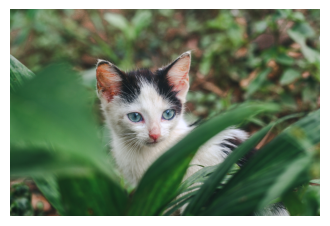

Q: What colour are the animal's eyes?
CLIP tags: cat (99%), dog (0%), person (0%)
A: The animal's eyes are blue.


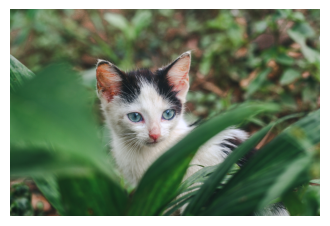

Q: Is there a bicycle?
CLIP tags: cat (99%), dog (0%), person (0%)
A: no


In [20]:
from pathlib import Path

DEFAULT_TAGS = ["cat", "dog", "person", "car", "bicycle", "horse", "bird", "food", "building",
                "landscape", "football", "airplane", "text document"]

def clip_tags(image, vocabulary=DEFAULT_TAGS, k=3):
    """Zero-shot CLIP tags = (label, probability) for the k most likely concepts."""
    logits = CLIP_SCALE * (clip_image_features(image) @ clip_text_features([f"a photo of a {v}" for v in vocabulary]).T)[0]
    p = logits.softmax(0).cpu()
    top = p.topk(min(k, len(vocabulary)))
    return [(vocabulary[i], v.item()) for v, i in zip(top.values, top.indices)]

def assistant(image, question, show=True, with_tags=False, max_new_tokens=150):
    """Multimodal Image Assistant. `image` = PIL image or file path. Returns the answer string."""
    if isinstance(image, (str, Path)):
        image = Image.open(image).convert("RGB")
    answer = ask_llava(image, question, max_new_tokens=max_new_tokens)
    if show:
        plt.figure(figsize=(4, 4)); plt.imshow(image); plt.axis("off"); plt.show()
        print("Q:", question)
        if with_tags:
            print("CLIP tags:", ", ".join(f"{t} ({p:.0%})" for t, p in clip_tags(image)))
        print("A:", answer)
    return answer

demo_image = "images/cat1.jpg"
for q in ["What is happening in this image?", "What colour are the animal's eyes?", "Is there a bicycle?"]:
    assistant(demo_image, q, with_tags=True)
    print("=" * 60)

##  Bonus: CLIP retrieval + LLaVA explanation  
(User query -> CLIP -> Top-K images -> LLaVA -> explanation)

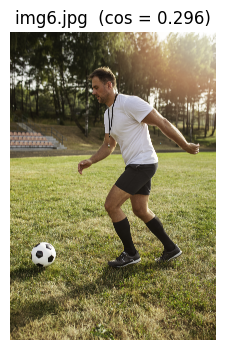

Yes, the image matches the search. The person is playing football, and the ball is on the ground in front of them. 



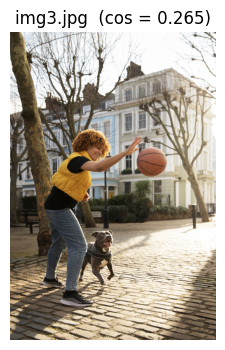

No, the image does not match the search. The search for "a person playing football" did not find any relevant information. The image shows a person with curly hair wearing a yellow vest and blue jeans, playing with a dog on a brick path. There are trees and buildings in the background, but no football is visible in the image. 



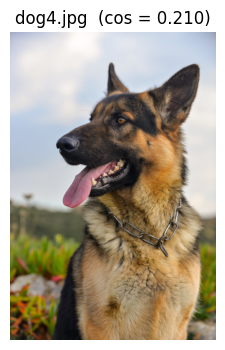

No, the image does not match the search. The search for "a person playing football" did not match the image. The image shows a German Shepherd dog with its tongue out, wearing a chain collar, and standing in a natural outdoor setting with greenery in the background. 



,Image,CLIP similarity,LLaVA explanation
0,img6.jpg,0.296,"Yes, the image matches the search. The person is playing football, and the ball is on the ground in front of them."
1,img3.jpg,0.265,"No, the image does not match the search. The search for ""a person playing football"" did not find any relevant information. The image shows a person with curly hair wearing a yellow vest and blue j..."
2,dog4.jpg,0.210,"No, the image does not match the search. The search for ""a person playing football"" did not match the image. The image shows a German Shepherd dog with its tongue out, wearing a chain collar, and ..."


In [21]:
def retrieve_and_explain(query, k=3, db_file="clip_image_database.pt", show=True):
    db = torch.load(db_file)                         # built in Exercise 7
    paths, emb = db["paths"], db["embeddings"].to(device)
    sims = (clip_text_features([query]) @ emb.T)[0]
    top = sims.topk(min(k, len(paths)))

    results = []
    for score, idx in zip(top.values.tolist(), top.indices.tolist()):
        img = Image.open(paths[idx]).convert("RGB")
        explanation = ask_llava(
            img,
            f'A user searched for: "{query}". Does this image match the search? '
            f'Answer in one or two sentences and explain what is visible that supports your answer.',
            max_new_tokens=80,
        )
        results.append({"Image": Path(paths[idx]).name, "CLIP similarity": round(score, 3), "LLaVA explanation": explanation})
        if show:
            plt.figure(figsize=(4, 4)); plt.imshow(img); plt.axis("off")
            plt.title(f"{Path(paths[idx]).name}  (cos = {score:.3f})"); plt.show()
            print(explanation, "\n")
    return pd.DataFrame(results)

df_bonus = retrieve_and_explain("a person playing football", k=3)
display(df_bonus)

# Conclusion

**What the experiments showed**

- **CLIP:** Matches images with text and can classify images without additional training. It achieved **100% accuracy (10/10 images)** in my cat/dog experiment. However, the dataset was small, its scores depend on the candidate labels, and prompt wording can affect the results. CLIP is useful for **image classification and image retrieval**.

- **LLaVA:** Generates image descriptions and answers questions about images. Unlike CLIP, it can produce natural-language responses. However, it can be slow on a CPU and may hallucinate details that are not present in the image.

- **Using both models:** CLIP can find relevant images, while LLaVA can describe them and answer questions. Combining them allows each model to perform the task it handles best.

**Limitations and future work**

The experiments used small datasets and manual evaluation, so the results are only indicative. Future work could use larger standard datasets, more powerful models, and more extensive evaluation.
